# Metropolis

**Seong Cho** · ACME Volume 3

**Lab objective:** use the Metropolis algorithm to sample spin configurations of an $n \times n$ lattice at several values of $\beta$.

<sub>Lab specification from the *Volume 3* lab materials of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the course's lab notebook. Solutions are my own.</sub>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Problem 1: A random spin configuration

> **Problem 1.** Write a function that accepts an integer $n$ and returns a random spin configuration for an $n \times n$ lattice (as an $n \times n$ NumPy array of $1$s and $-1$s).
> Test your function with $n = 100$, plotting the spin configuration via `plt.imshow()`.

In [2]:
def random_lattice(n):
    """Construct a random spin configuration for an nxn lattice."""
    lattice = np.random.binomial(1, 0.5, size=(n,n))
    return 2*lattice - 1

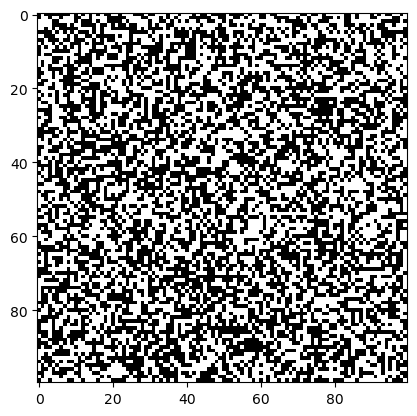

In [3]:
np.random.seed(1)
lattice = random_lattice(100)
plt.imshow(lattice, cmap="gray")
plt.show()

In [4]:
print("fraction of spins equal to 1:", (lattice == 1).mean())
assert lattice.shape == (100, 100) and set(np.unique(lattice)) == {-1, 1}

fraction of spins equal to 1: 0.501


## Problem 2: The energy of a spin configuration

> **Problem 2.** Write a function that accepts a spin configuration $\sigma$ for a lattice as a NumPy array.
> Compute the energy $H(\sigma)$ of the spin configuration.
> Be careful to not double count site pair interactions!

In [5]:
def lattice_energy(L):
    """Computer the energy of the spin configuration corresponding to the
    lattice L.
    """
    # Horizontal sums
    s1 = (L * np.roll(L, 1, axis=0)).sum()
    # Vertical sums
    s2 = (L * np.roll(L, 1, axis=1)).sum()
    return -(s1 + s2)

In [6]:
np.random.seed(2)
lattice_energy(random_lattice(100))

np.int64(132)

Check against a direct double loop that visits every site once and counts its pairs with the neighbor below and the neighbor to the right (with the same wrap-around boundary as the code above), so each site pair is counted exactly once:

In [7]:
def energy_loop(L):
    n = len(L)
    H = 0
    for i in range(n):
        for j in range(n):
            H -= L[i, j] * (L[(i+1) % n, j] + L[i, (j+1) % n])
    return H

for n in [3, 4, 7, 10, 25]:
    for _ in range(5):
        L = random_lattice(n)
        assert lattice_energy(L) == energy_loop(L)
assert lattice_energy(np.ones((10, 10), dtype=int)) == -200     # 2 pairs per site, all aligned.

## Problem 3: Choosing a site to flip

> **Problem 3.** Write a function that accepts an integer $n$ and chooses a pair of indices $(i,j)$ where $0 \le i,j \le n-1$.
> Each possible pair should have an equal probability $\frac{1}{n^2}$ of being chosen.

In [8]:
def flip_location(n):
    """Choose a random pair of indices 0 <= i,j <= n-1."""
    i = np.random.randint(0, n)
    j = np.random.randint(0, n)
    return i,j

In [9]:
np.random.seed(3)
flip_location(100)

(24, 3)

Check: on a $5 \times 5$ lattice, the counts of $50{,}000$ draws are consistent with the uniform distribution (chi-square test, `scipy.stats.chisquare`).

In [10]:
from scipy.stats import chisquare

counts = np.zeros((5, 5))
for _ in range(50000):
    counts[flip_location(5)] += 1
p = chisquare(counts.ravel()).pvalue
print(counts.astype(int))
print("chi-square p-value:", p)
assert counts.sum() == 50000 and p > 0.001

[[1961 1995 2002 2038 2055]
 [1937 2026 1967 1986 2075]
 [2000 2012 1947 1988 1947]
 [2005 1990 2017 1957 2092]
 [1946 2053 1987 2005 2012]]
chi-square p-value: 0.689073612922199


## Problem 4: Updating the energy after one flip

> **Problem 4.** Write a function that accepts a spin configuration $\sigma$, its energy $H(\sigma)$, and integer indices $i$ and $j$.
> Compute the energy of the new spin configuration $\sigma^*$, which is $\sigma$ but with the spin flipped at the $(i,j)$th entry of the corresponding lattice.
> Do not explicitly construct the new lattice for $\sigma^*$.

In [11]:
def updated_energy(L, L_energy, i, j):
    """Compute the energy of the spin configuration that results
    when the (i,j)th spin of L is flipped.
    """
    n = len(L)
    # Update the energy using Equation 1.2
    sum_factor = L[i,j]*(L[(i+1) % n,j] + L[i-1, j] + L[i,(j+1) % n] + L[i,j-1])
    return L_energy + 2*sum_factor

In [12]:
np.random.seed(5)
n = 100
# Make random lattice and calculate the energy
L = random_lattice(n)
L_energy = lattice_energy(L)
# Choose a random point to flip
i,j = flip_location(n)
# Create a new lattice with the point flipped
L_new = L.copy()
L_new[i,j] = 1 if L[i,j] == -1 else -1
# Calculate the new energy using updated_energy
e = updated_energy(L, L_energy, i, j)
print(e)
# Calculate the new energy using the new lattice
print(lattice_energy(L_new))
# Compare to the old energy
print(L_energy)

-280
-280
-272


The same comparison for many random lattices and sites, including sites on the edges of the lattice; `updated_energy()` leaves the lattice unchanged.

In [13]:
for _ in range(1000):
    n = np.random.randint(3, 30)
    L = random_lattice(n)
    L_before = L.copy()
    i, j = flip_location(n)
    e = updated_energy(L, lattice_energy(L), i, j)
    assert np.array_equal(L, L_before)
    L[i, j] *= -1
    assert e == lattice_energy(L)

## Problem 5: The acceptance step

> **Problem 5.** Write a function that accepts a float $\beta$ and spin configuration energies $H(\sigma)$ and $H(\sigma^*)$.
> Calculate whether or not the new spin configuration $\sigma^*$ should be accepted (return `True` or `False`).

In [14]:
def accept(beta, energy_old, energy_new):
    """Accept or reject the new spin configuration."""
    log_ratio = beta * (energy_old - energy_new)
    # Accept automatically if ratio > 1
    if log_ratio > 0:
        return True
    else:
        # Choose a uniform random between 0 and 1 and determine whether to accept the lattice
        u = np.random.uniform()
        if np.log(u) <= log_ratio:
            return True
        else: return False

Check: a move that lowers the energy is always accepted, and one that raises it by $\Delta H$ is accepted with frequency close to $e^{-\beta \Delta H}$.

In [15]:
np.random.seed(5)
assert all(accept(0.4, -100, -108) for _ in range(1000))
for beta, dH in [(0.2, 4), (0.4, 4), (1, 1), (1, 4)]:
    freq = np.mean([accept(beta, 0, dH) for _ in range(20000)])
    print("beta = {}, dH = {}: accepted {:.4f}, exp(-beta*dH) = {:.4f}".format(beta, dH, freq, np.exp(-beta*dH)))
    assert abs(freq - np.exp(-beta*dH)) < 0.015

beta = 0.2, dH = 4: accepted 0.4458, exp(-beta*dH) = 0.4493
beta = 0.4, dH = 4: accepted 0.2029, exp(-beta*dH) = 0.2019
beta = 1, dH = 1: accepted 0.3708, exp(-beta*dH) = 0.3679
beta = 1, dH = 4: accepted 0.0176, exp(-beta*dH) = 0.0183


## Problem 6: The Metropolis sampler

> **Problem 6.** Write a function that accepts a float $\beta>0$ and integers $n$, `n_samples`, and `burn_in`.
> Initialize an $n\times n$ lattice for a spin configuration $\sigma$ using `random_lattice()`.
> Use the Metropolis algorithm to (potentially) update the lattice `burn_in` times.
> 1. Use `flip_location()` to choose a site for possibly flipping the spin, thus defining a potential new configuration $\sigma^*$.
> 2. Use `updated_energy()` to calculate the energy $H(\sigma^*)$ of the proposed configuration.
> 3. Use `accept()` to accept or reject the proposed configuration. If it is accepted, set $\sigma = \sigma^*$ by flipping the spin at the indicated site.
> 4. Track $-\beta H(\sigma)$ at each iteration (independent of acceptance).
>
> After the burn-in period, continue the iteration `n_samples` times, also recording every $100$th sample (to prevent memory failure).
> Return the samples, the sequence of weighted energies $-\beta H(\sigma)$, and the acceptance rate.
>
> Test your sampler on a $100 \times 100$ grid with $200000$ total iterations, with `n_samples` large enough so that you will keep $50$ samples, for $\beta = 0.2, 0.4, 1$.
> Plot the proportional log probabilities, as well as a late sample from each test.

In [16]:
def ising_metropolis(beta, n=100, n_samples=5000, burn_in=195000):
    """Use the Metropolis algorithm to choose new spin configurations.

    Parameters:
        beta (float > 0): Constant inversely proportional to the temperature.
        N (int > 0): The size of the lattice.
        n_samples (int): The number of samples to generate.
        burnin (int): The number of iterations to burn before sampling.

    Returns:
        ((n_samples//100, n,n) ndarray): The sampled spin configurations.
        (n_samples) ndarray: The weighted energies of each configuration.
        (float): The proportion of proposed samples that were accepted.
    """
    # Initialize random lattice
    L = random_lattice(n)
    weighted_energy = []
    samples = []
    accept_count = 0
    for k in range(burn_in + n_samples):
        i,j = flip_location(n)
        # Update energy
        energy_old = lattice_energy(L)
        energy_new = updated_energy(L, energy_old, i, j)
        # Flip the splin if accepted
        if accept(beta, energy_old, energy_new):
            L[i,j] = 1 if L[i,j] == -1 else -1
            accept_count+=1
        weighted_energy.append(-beta * energy_old)
        # After the burn in period, record several samples
        if k >= burn_in:
            if k % 100 == 0:
                # Changed: store a copy. Appending L itself stored 50 references to the one
                # lattice that keeps changing, so every returned sample was the final lattice.
                samples.append(L.copy())
    return samples, weighted_energy, accept_count / (burn_in + n_samples)

A check applied to each test below: $50$ samples and $200{,}000$ weighted energies are returned, and each sample is a separate snapshot, whose energy is the one recorded at the start of the next iteration (sample $s$ is taken after iteration $k = 195000 + 100s$).

In [17]:
def check_run(beta, samples, weighted_energy, rate):
    print("acceptance rate: {:.4f}".format(rate))
    assert len(samples) == 50 and len(weighted_energy) == 200000
    for s, k in enumerate(range(195000, 200000, 100)):
        assert np.isclose(-beta * lattice_energy(samples[s]), weighted_energy[k+1])

### Beta = 0.2

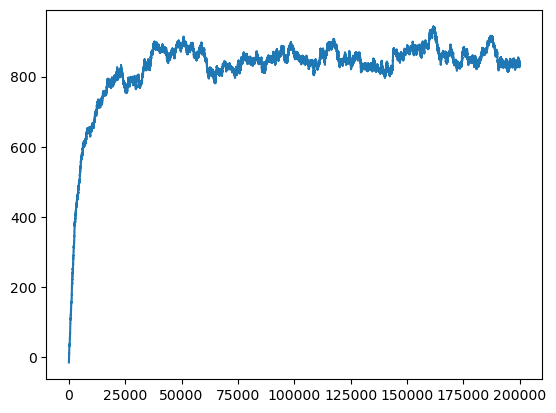

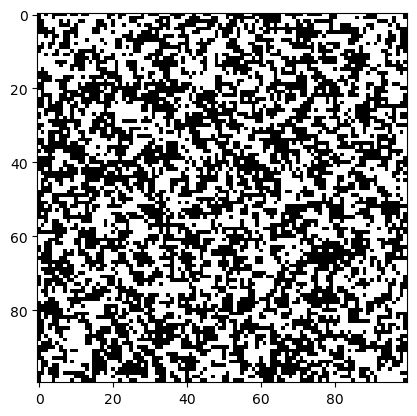

In [18]:
np.random.seed(6)
samples, weighted_energy, rate = ising_metropolis(0.2, n=100, n_samples=5000, burn_in=195000)
plt.plot(weighted_energy)
plt.show()
plt.imshow(samples[-1], cmap="gray")
plt.show()

In [19]:
check_run(0.2, samples, weighted_energy, rate)

acceptance rate: 0.6962


### Beta = 0.4

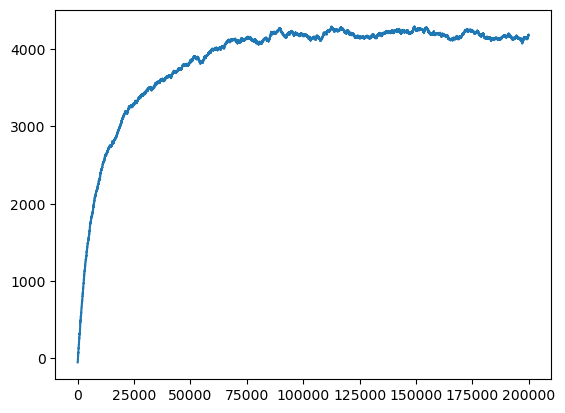

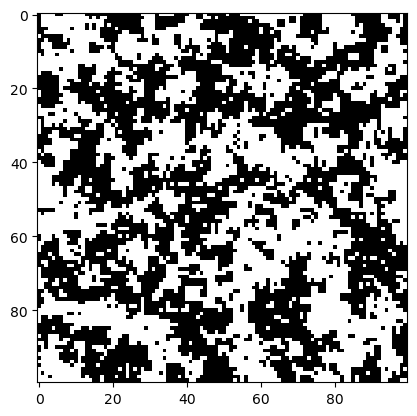

In [20]:
np.random.seed(7)
samples, weighted_energy, rate = ising_metropolis(0.4, n=100, n_samples=5000, burn_in=195000)
plt.plot(weighted_energy)
plt.show()
plt.imshow(samples[-1], cmap="gray")
plt.show()

In [21]:
check_run(0.4, samples, weighted_energy, rate)

acceptance rate: 0.3785


### Beta = 1

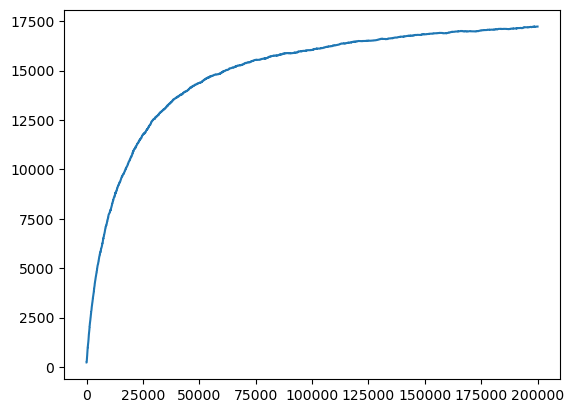

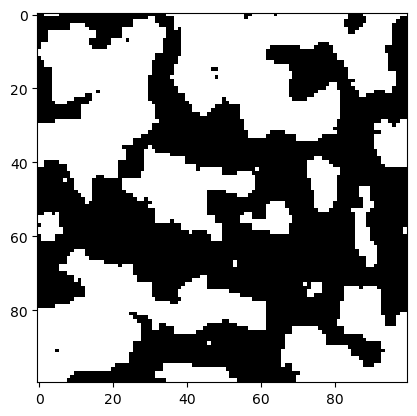

In [22]:
np.random.seed(8)
samples, weighted_energy, rate = ising_metropolis(1, n=100, n_samples=5000, burn_in=195000)
plt.plot(weighted_energy)
plt.show()
plt.imshow(samples[-1], cmap="gray")
plt.show()

In [23]:
check_run(1, samples, weighted_energy, rate)

acceptance rate: 0.1351
